# 02 — Análise causal

> Este notebook continua a análise exploratória (`01_eda.ipynb`) e responde às hipóteses
> causais com que ela terminou. Ele usa só o arquivo de dados, a base limpa que a EDA validou
> e um modelo e uma simulação construídos aqui mesmo — nenhum resultado de outro documento do
> projeto entra como premissa. A seção 7 compara, no fim, com o que o repositório publica.
>
> Para reexecutar: `poetry install --with notebooks` e depois `make causal`.

**Duas perguntas, duas partes:**

1. **Idade e risco** (hipóteses H-a e H-d da EDA). A inadimplência cai com a idade. Quanto
   dessa diferença passa pelo comportamento de crédito, e quanto a limpeza da base altera?
   Responde-se com o dado observado.
2. **Degradação do modelo** (hipóteses H-b e H-c). Quando a economia muda, por que um modelo
   de crédito piora? Responde-se intervindo num cenário simulado, um fator de cada vez.

## 0. O que dá para afirmar sobre causa, e com base em quê

Correlação não identifica causa sozinha. Toda conclusão causal depende de um modelo de como
as variáveis se influenciam — um **grafo causal (DAG)** — e de suposições que precisam ser
ditas. Este notebook separa três tipos de afirmação:

| Tipo | O que é | Exemplo |
|---|---|---|
| **Fato do dado** | medido no arquivo, na EDA ou aqui | o alvo descreve os dois anos *seguintes* às variáveis (EDA, seção 1) |
| **Fato lógico** | verdadeiro por definição | nenhuma variável da base causa a idade de alguém |
| **Suposição** | necessária, não testável com este dado | não existe fator oculto que mova ao mesmo tempo o uso do crédito e a inadimplência |

Cada resultado abaixo diz de quais desses tipos ele depende.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyBboxPatch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

from credito.config import get_settings
from credito.data.arff import ler_arff
from credito.data.prepare import limpar, separar
from credito.schema import ALVO, ALVO_ORIGINAL, FEATURES

pd.options.display.float_format = "{:,.4f}".format

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2,
        "axes.labelcolor": TINTA_2,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.grid.axis": "y",
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "font.size": 10,
        "legend.frameon": False,
    }
)

settings = get_settings()
SEMENTE = settings.random_seed
NOMES = {
    "RevolvingUtilizationOfUnsecuredLines": "uso_rotativo",
    "age": "idade",
    "NumberOfTime30-59DaysPastDueNotWorse": "atraso_30_59",
    "DebtRatio": "razao_divida",
    "MonthlyIncome": "renda_mensal",
    "NumberOfOpenCreditLinesAndLoans": "linhas_abertas",
    "NumberOfTimes90DaysLate": "atraso_90",
    "NumberRealEstateLoansOrLines": "imobiliario",
    "NumberOfTime60-89DaysPastDueNotWorse": "atraso_60_89",
    "NumberOfDependents": "dependentes",
}
X = list(FEATURES)
MEDIADORES = [c for c in X if c != "age"]

bruto = ler_arff(settings.dataset_path)
referencia, _ = limpar(bruto)  # as regras derivadas e conferidas na EDA, seção 2.4
particoes = separar(
    referencia,
    test_size=settings.test_size,
    validation_size=settings.validation_size,
    seed=SEMENTE,
)
treino, validacao = particoes["treino"], particoes["validacao"]
tamanhos = {nome: f"{len(p):,}" for nome, p in particoes.items()}
print(f"partições: {tamanhos} — o teste não é usado aqui")

partições: {'treino': '70,749', 'validacao': '23,584', 'teste': '23,584'} — o teste não é usado aqui


A partição de **teste não é tocada** neste notebook: ela fica reservada para avaliar modelos
depois. A parte 1 estima no treino; a parte 2 treina no treino e mede a degradação na
validação.

---

# Parte 1 — Idade e risco

## 1. O grafo causal

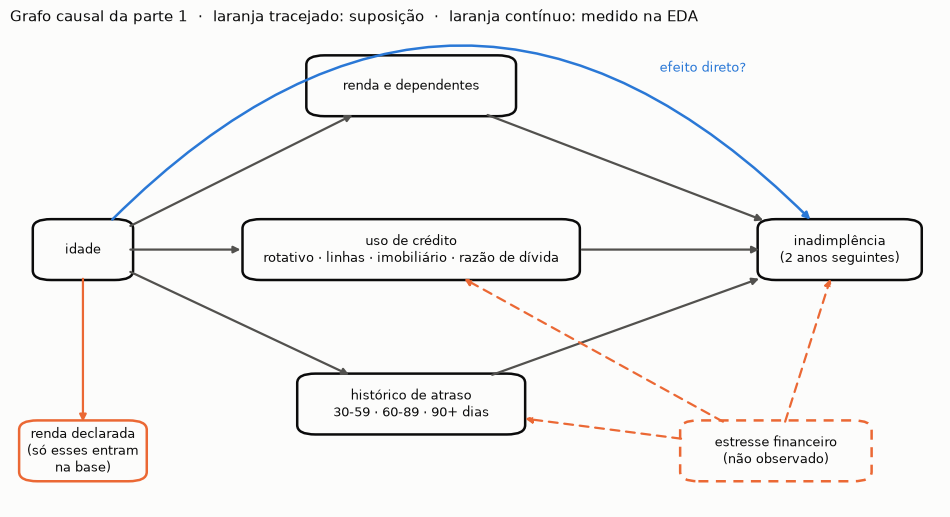

In [2]:
fig, ax = plt.subplots(figsize=(12, 6.2))
ax.set_xlim(-0.02, 1.0)
ax.set_ylim(0.0, 1.02)
ax.axis("off")
ax.grid(False)
ALTURA = 0.12
NOS = {}


def no(chave, x, y, texto, largura, cor=TINTA, tracejado=False):
    NOS[chave] = (x, y, largura)
    ax.add_patch(
        FancyBboxPatch(
            (x - largura / 2, y - ALTURA / 2),
            largura,
            ALTURA,
            boxstyle="round,pad=0.005,rounding_size=0.02",
            facecolor=FUNDO,
            edgecolor=cor,
            linewidth=1.8,
            linestyle=(0, (4, 3)) if tracejado else "solid",
        )
    )
    ax.text(x, y, texto, ha="center", va="center", fontsize=9.5, color=TINTA)


def borda(origem, destino):
    # Ponto onde a reta entre os dois centros sai da caixa de origem.
    x, y, largura = NOS[origem]
    dx, dy = NOS[destino][0] - x, NOS[destino][1] - y
    t = min(largura / 2 / abs(dx) if dx else np.inf, ALTURA / 2 / abs(dy) if dy else np.inf)
    return x + dx * t * 1.04, y + dy * t * 1.04


def seta(origem, destino, cor=TINTA_2, tracejado=False):
    ax.annotate(
        "",
        xy=borda(destino, origem),
        xytext=borda(origem, destino),
        arrowprops=dict(
            arrowstyle="-|>",
            color=cor,
            linewidth=1.6,
            shrinkA=0,
            shrinkB=0,
            linestyle=(0, (4, 3)) if tracejado else "solid",
        ),
    )


no("idade", 0.06, 0.55, "idade", 0.1)
no("renda", 0.42, 0.9, "renda e dependentes", 0.22)
no("uso", 0.42, 0.55, "uso de crédito\nrotativo · linhas · imobiliário · razão de dívida", 0.36)
no("atraso", 0.42, 0.22, "histórico de atraso\n30-59 · 60-89 · 90+ dias", 0.24)
no("y", 0.89, 0.55, "inadimplência\n(2 anos seguintes)", 0.17)
no("oculto", 0.82, 0.12, "estresse financeiro\n(não observado)", 0.2, cor=LARANJA, tracejado=True)
no("selecao", 0.06, 0.12, "renda declarada\n(só esses entram\nna base)", 0.13, cor=LARANJA)

for meio in ("renda", "uso", "atraso"):
    seta("idade", meio)
    seta(meio, "y")
for alvo in ("uso", "atraso", "y"):
    seta("oculto", alvo, cor=LARANJA, tracejado=True)
seta("idade", "selecao", cor=LARANJA)
ax.annotate(
    "",
    xy=(0.86, 0.61),
    xytext=(0.09, 0.61),
    arrowprops=dict(arrowstyle="-|>", color=AZUL, linewidth=1.8, connectionstyle="arc3,rad=-0.5"),
)
ax.text(0.74, 0.93, "efeito direto?", ha="center", color=AZUL, fontsize=9.5)
ax.set_title(
    "Grafo causal da parte 1  ·  laranja tracejado: suposição  ·  laranja contínuo: medido na EDA",
    loc="left",
)
plt.show()

**Como ler o grafo, seta a seta:**

| Elemento | Tipo | Base |
|---|---|---|
| Nenhuma seta sai da inadimplência | fato do dado | o alvo descreve os dois anos seguintes (EDA, seção 1) |
| Nenhuma seta entra na idade | fato lógico | nada na base causa a idade de alguém |
| Idade → renda, uso de crédito, atraso → inadimplência | suposição de direção | idade vem antes de tudo; o que se mede é *quanto* passa por esses caminhos |
| Idade → seleção | fato do dado | quem não declara renda é mais velho (EDA, seção 3) |
| Estresse financeiro oculto → uso, atraso, inadimplência, seleção | **suposição** | plausível, não observável — é a principal ameaça da seção 3 |

**Duas consequências** decidem o que é estimável:

1. Como nada causa a idade, **o efeito total da idade sobre o risco é a própria diferença
   observada** entre faixas etárias — não existe confundidor para ajustar. Isso depende só de
   um fato lógico. Com uma ressalva: vale *dentro da base selecionada*, porque a seleção
   depende da idade. A seção 2 mede o tamanho dessa ressalva.
2. **Separar efeito direto e mediado exige uma suposição a mais**: que nenhum fator oculto
   mova ao mesmo tempo o comportamento de crédito e a inadimplência. O estresse financeiro do
   grafo viola isso. A seção 3 estima a decomposição mesmo assim e diz como lê-la.

## 2. A seleção altera a relação entre idade e risco? (H-d)

O arquivo bruto tem idade e alvo para **todo mundo**, inclusive para quem a limpeza descarta.
Então dá para comparar a relação entre idade e risco antes e depois da seleção.

In [3]:
FAIXAS = [17, 25, 40, 60, 200]
ROTULOS = ["18-25", "26-40", "41-60", "61+"]

y_bruto = (bruto[ALVO_ORIGINAL] == "Yes").astype(int)
valido = bruto["age"] >= 18  # a única idade impossível do arquivo é 0 (EDA, seção 2.3)
faixa_bruto = pd.cut(bruto.loc[valido, "age"], FAIXAS, labels=ROTULOS)
faixa_ref = pd.cut(referencia["age"], FAIXAS, labels=ROTULOS)

selecao = pd.DataFrame(
    {
        "linhas no bruto": faixa_bruto.value_counts().sort_index(),
        "linhas na base limpa": faixa_ref.value_counts().sort_index(),
        "inadimplência no bruto": y_bruto[valido].groupby(faixa_bruto, observed=True).mean(),
        "inadimplência na base limpa": referencia.groupby(faixa_ref, observed=True)[ALVO].mean(),
    }
)
selecao["% removido"] = (1 - selecao["linhas na base limpa"] / selecao["linhas no bruto"]) * 100
selecao["inadimplência de quem saiu"] = (
    selecao["inadimplência no bruto"] * selecao["linhas no bruto"]
    - selecao["inadimplência na base limpa"] * selecao["linhas na base limpa"]
) / (selecao["linhas no bruto"] - selecao["linhas na base limpa"])
display(selecao)

razao_bruto = (
    selecao.loc["18-25", "inadimplência no bruto"] / selecao.loc["61+", "inadimplência no bruto"]
)
razao_ref = (
    selecao.loc["18-25", "inadimplência na base limpa"]
    / selecao.loc["61+", "inadimplência na base limpa"]
)
print(f"razão de risco 18-25 / 61+: bruto {razao_bruto:.2f}x | base limpa {razao_ref:.2f}x")

,linhas no bruto,linhas na base limpa,inadimplência no bruto,inadimplência na base limpa,% removido,inadimplência de quem saiu
age,,,,,,
18-25,3027,2219,0.1117,0.1009,26.6931,0.1411
26-40,32069,27022,0.1028,0.1008,15.7379,0.1131
41-60,69843,56509,0.0722,0.0738,19.0914,0.0652
61+,45060,32167,0.0300,0.0331,28.6130,0.0221


razão de risco 18-25 / 61+: bruto 3.73x | base limpa 3.05x


A limpeza não remove as idades por igual: tira de 27% a 29% das pontas (18-25 e 61+) e de 16%
a 19% do meio. E **quem sai difere de quem fica em direções opostas conforme a idade**: entre
os 18-25, quem sai inadimple mais (14,1% contra 10,1% de quem fica); entre os 61+, menos (2,2%
contra 3,3%).

O efeito líquido é que **a seleção comprime a diferença entre as idades**: a razão de risco
entre 18-25 e 61+ é de 3,73 vezes no arquivo bruto e de 3,05 vezes na base limpa — cerca de
18% menor.

Isso também resolve um aparente conflito com a EDA, onde quem não declara renda inadimplia
*menos* no agregado. No agregado, quem sai é menos arriscado porque é mais velho; dentro da
faixa jovem, é mais arriscado. É um caso pequeno de paradoxo de Simpson: a composição por
idade inverte a comparação.

**H-d: confirmada, com direção medida.** A seleção está associada à idade e ao risco, e
**atenua** a relação entre os dois. Qualquer diferença por idade medida na base limpa — no
modelo ou na auditoria de equidade — subestima a da população que chega no arquivo. (A
remoção inclui todas as regras da limpeza; a de renda ausente responde por 91% dela.)

## 3. Quanto da diferença entre idades passa pelo comportamento de crédito? (H-a)

**A pergunta, em termos que dá para calcular:** se as pessoas de uma faixa jovem tivessem a
renda, o uso de crédito e o histórico de atraso **típicos das pessoas de 61+**, quanto do seu
excesso de risco sumiria?

**Como se calcula (padronização, ou g-computação):**

1. Um modelo flexível estima o risco a partir da idade **e** de todas as outras variáveis:
   $\hat{p}(\text{idade}, M)$, onde $M$ são as nove variáveis que não são idade.
2. Três quantidades, para uma faixa jovem $j$ contra a faixa 61+ ($v$):
   - $\psi(j, j)$: risco médio previsto para os jovens, com os seus próprios $M$;
   - $\psi(j, v)$: risco médio previsto se pessoas com os $M$ dos 61+ tivessem as idades
     dos jovens — cada linha 61+ recebe uma idade sorteada da faixa jovem;
   - $\psi(v, v)$: risco médio previsto para os 61+, com os seus próprios $M$.
3. A diferença total se divide em duas partes que somam exatamente o total:
   - **pelo comportamento** (mediada): $\psi(j, j) - \psi(j, v)$ — o que muda quando só o
     perfil de crédito muda;
   - **pela idade, com o comportamento fixo** (direta): $\psi(j, v) - \psi(v, v)$.

O intervalo de confiança vem de 200 reamostragens do treino, **reajustando o modelo em cada
uma**.

In [4]:
def modelo_de_risco(frame: pd.DataFrame, semente: int) -> HistGradientBoostingClassifier:
    return HistGradientBoostingClassifier(random_state=semente).fit(frame[X], frame[ALVO])


def decompor(frame: pd.DataFrame, semente: int) -> pd.DataFrame:
    modelo = modelo_de_risco(frame, semente)
    gerador = np.random.default_rng(semente)
    faixa = pd.cut(frame["age"], FAIXAS, labels=ROTULOS)
    velhos = frame[faixa == "61+"]
    psi_vv = modelo.predict_proba(velhos[X])[:, 1].mean()
    linhas = {}
    for jovem in ROTULOS[:-1]:
        grupo = frame[faixa == jovem]
        psi_jj = modelo.predict_proba(grupo[X])[:, 1].mean()
        contrafactual = velhos.assign(age=gerador.choice(grupo["age"].to_numpy(), size=len(velhos)))
        psi_jv = modelo.predict_proba(contrafactual[X])[:, 1].mean()
        linhas[jovem] = {
            "diferença total": psi_jj - psi_vv,
            "pelo comportamento": psi_jj - psi_jv,
            "pela idade (direta)": psi_jv - psi_vv,
        }
    return pd.DataFrame(linhas).T


pontual = decompor(treino, SEMENTE)
reamostras = []
gerador = np.random.default_rng(SEMENTE)
for b in range(200):
    amostra = treino.sample(len(treino), replace=True, random_state=int(gerador.integers(2**31)))
    reamostras.append(decompor(amostra, b).assign(reamostra=b))
reamostras = pd.concat(reamostras).rename_axis("faixa").reset_index()

ic = reamostras.groupby("faixa")[list(pontual.columns)].quantile([0.025, 0.975]).unstack()
resultado = pontual.copy()
for coluna in pontual.columns:
    resultado[f"{coluna} IC95"] = [
        f"[{ic.loc[f, (coluna, 0.025)]:+.4f}, {ic.loc[f, (coluna, 0.975)]:+.4f}]"
        for f in pontual.index
    ]
resultado["% pelo comportamento"] = pontual["pelo comportamento"] / pontual["diferença total"] * 100
fracao = reamostras["pelo comportamento"] / reamostras["diferença total"] * 100
limites = fracao.groupby(reamostras["faixa"]).quantile([0.025, 0.975]).unstack()
resultado["% IC95"] = [
    f"[{limites.loc[f, 0.025]:.0f}%, {limites.loc[f, 0.975]:.0f}%]" for f in pontual.index
]
display(
    resultado[
        [
            "diferença total",
            "diferença total IC95",
            "pelo comportamento",
            "pelo comportamento IC95",
            "pela idade (direta)",
            "pela idade (direta) IC95",
            "% pelo comportamento",
            "% IC95",
        ]
    ]
)

,diferença total,diferença total IC95,pelo comportamento,pelo comportamento IC95,pela idade (direta),pela idade (direta) IC95,% pelo comportamento,% IC95
18-25,0.0679,"[+0.0557, +0.0909]",0.0315,"[-0.0122, +0.0441]",0.0364,"[+0.0272, +0.0887]",46.3972,"[-18%, 59%]"
26-40,0.0647,"[+0.0614, +0.0714]",0.0472,"[+0.0437, +0.0528]",0.0175,"[+0.0140, +0.0226]",72.9356,"[66%, 78%]"
41-60,0.0390,"[+0.0368, +0.0433]",0.0312,"[+0.0296, +0.0339]",0.0078,"[+0.0056, +0.0107]",80.0611,"[75%, 85%]"


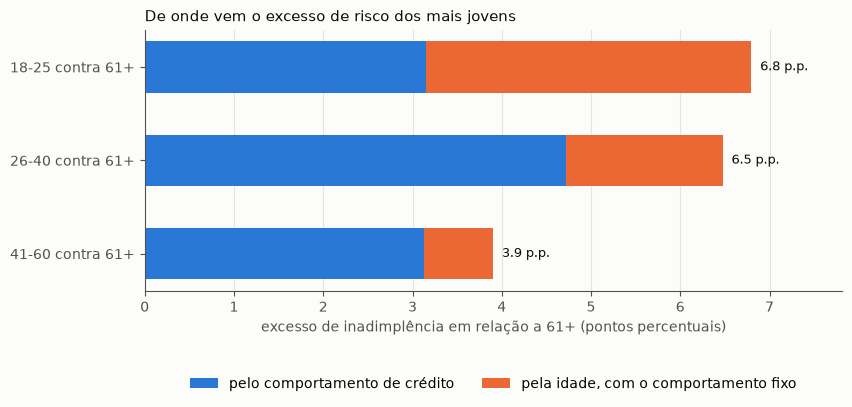

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(pontual))[::-1]
comportamento = pontual["pelo comportamento"] * 100
direta = pontual["pela idade (direta)"] * 100
ax.barh(y, comportamento, color=AZUL, height=0.55, label="pelo comportamento de crédito")
ax.barh(
    y,
    direta,
    left=comportamento,
    color=LARANJA,
    height=0.55,
    label="pela idade, com o comportamento fixo",
)
for yi, total in zip(y, pontual["diferença total"] * 100, strict=True):
    ax.text(total + 0.1, yi, f"{total:.1f} p.p.", va="center", color=TINTA, fontsize=9)
ax.set_yticks(y, [f"{f} contra 61+" for f in pontual.index])
ax.set_xlabel("excesso de inadimplência em relação a 61+ (pontos percentuais)")
ax.set_xlim(0, (pontual["diferença total"].max() * 100) * 1.15)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
ax.set_title("De onde vem o excesso de risco dos mais jovens", loc="left")
plt.show()

| Faixa contra 61+ | Excesso de risco | Pelo comportamento de crédito | Pela idade, com o comportamento fixo |
|---|---:|---:|---:|
| 26-40 | 6,5 p.p. | **73%** (IC 95% de 66% a 78%) | 1,8 p.p., IC acima de zero |
| 41-60 | 3,9 p.p. | **80%** (IC 95% de 75% a 85%) | 0,8 p.p., IC acima de zero |
| 18-25 | 6,8 p.p. | 46%, mas o IC vai de −18% a 59% | 3,6 p.p. |

- **Entre 26 e 60 anos, três quartos ou mais do excesso de risco em relação aos 61+ vêm
  acompanhados de um comportamento de crédito diferente.** O resto permanece mesmo com o
  comportamento igualado, e o intervalo dessa parte direta fica acima de zero.
- **Para 18-25 não há conclusão.** São 1.273 pessoas no treino; o intervalo da parte mediada
  cruza o zero. A amostra não sustenta a decomposição nessa faixa.

**Como ler, dada a suposição que a decomposição exige.** Se um estresse financeiro não
observado move ao mesmo tempo o uso do crédito e a inadimplência, parte do que aparece como
"pelo comportamento" é esse estresse se manifestando no comportamento. A leitura robusta,
que não depende da suposição, é a descritiva: **a maior parte da diferença entre idades
anda junto com uma diferença de comportamento de crédito**.

**A consequência prática para equidade:** retirar a idade do modelo removeria, no máximo, a
parte direta — entre 20% e 27% da diferença, nas faixas onde a estimativa é
estável. Um modelo sem idade continuaria tratando as idades de forma diferente, através das
variáveis de comportamento. A auditoria de viés precisa olhar para elas, não só para a idade.

### 3.1 Por qual variável passa a parte mediada?

Repetindo o contrafactual uma variável de cada vez: as pessoas 61+ recebem a idade dos jovens
**e** o valor dessa variável sorteado entre os jovens, mantendo todas as outras como são. É
uma leitura aproximada — as variáveis não são independentes, então as partes não somam o
total —, mas mostra onde está o grosso.

In [6]:
modelo = modelo_de_risco(treino, SEMENTE)
faixa_treino = pd.cut(treino["age"], FAIXAS, labels=ROTULOS)
velhos = treino[faixa_treino == "61+"]
jovens = treino[faixa_treino.isin(["18-25", "26-40"])]
gerador = np.random.default_rng(SEMENTE)
indices = gerador.integers(len(jovens), size=len(velhos))
so_idade = velhos.assign(age=jovens["age"].to_numpy()[indices])
base_jv = modelo.predict_proba(so_idade[X])[:, 1].mean()
por_variavel = {}
for coluna in MEDIADORES:
    trocado = so_idade.assign(**{coluna: jovens[coluna].to_numpy()[indices]})
    por_variavel[NOMES[coluna]] = (modelo.predict_proba(trocado[X])[:, 1].mean() - base_jv) * 100
por_variavel = pd.Series(por_variavel, name="p.p. acrescentados").sort_values(ascending=False)
display(por_variavel.to_frame())

,p.p. acrescentados
uso_rotativo,2.6802
atraso_90,1.0169
atraso_60_89,0.4628
atraso_30_59,0.3643
renda_mensal,0.1996
dependentes,0.0718
razao_divida,-0.0900
imobiliario,-0.2049
linhas_abertas,-0.3318


**O uso do rotativo é o principal caminho.** Dar às pessoas 61+ o uso de rotativo típico das
pessoas de 18 a 40 anos acrescenta 2,7 pontos percentuais ao risco previsto — mais que todas
as outras variáveis juntas. Depois vêm os atrasos de 90 dias ou mais (1,0 p.p.) e os outros
dois atrasos (0,4 p.p. cada). Renda e dependentes quase não contribuem. Linhas abertas,
imobiliário e razão de dívida empurram levemente para o lado oposto.

**H-a: confirmada.** O efeito da idade sobre o risco é, em grande parte, acompanhado pelo uso
do rotativo — a mesma variável que a EDA apontou como a mais preditiva da base (IV 1,03).

---

# Parte 2 — Por que o modelo degrada

## 4. Três jeitos de a economia mudar, e o que cada um faz com o dado

O enunciado fala em mudanças econômicas: inflação e novos perfis de clientes. Para estudar a
causa da degradação é preciso dizer **por qual caminho** cada mudança chega ao modelo. Há três
caminhos distintos, e cada um muda uma parte diferente da distribuição conjunta de $X$
(variáveis) e $Y$ (inadimplência):

| Choque | O que muda | O que não muda | Como se simula, sem inventar o rótulo |
|---|---|---|---|
| **Inflação** | a renda **nominal** de cada pessoa | a capacidade real de pagar — logo, o desfecho de cada pessoa | multiplica a renda por $(1 + \pi)$; o alvo de cada pessoa fica igual |
| **Novos perfis** | a **mistura** de pessoas que pedem crédito | a relação entre perfil e risco | reamostra pessoas reais da validação, com mais peso para quem tem até 40 anos; cada uma leva o seu alvo verdadeiro |
| **Crise** | o **risco** de pessoas com o mesmo perfil | as variáveis | uma fração dos adimplentes passa a inadimplir |

As duas primeiras **não precisam de nenhuma suposição sobre o alvo**: ou o alvo de cada
pessoa fica o mesmo, ou se reamostram pessoas reais com o seu alvo real. Só a crise precisa
de uma suposição — *quem* passa a inadimplir —, e a seção 5 mostra que essa escolha muda o
resultado.

Duas suposições ficam declaradas:
- na inflação, a razão de dívida não muda, porque pagamentos e custo de vida sobem junto com
  a renda;
- na crise, o choque atinge adimplentes ao acaso, sem preferência de perfil, no cenário
  principal.

**O modelo de trabalho** é um gradient boosting com as dez variáveis, treinado no treino e
avaliado na validação. Não é o baseline do projeto: é o instrumento desta análise.

In [7]:
modelo = modelo_de_risco(treino, SEMENTE)
p_base = modelo.predict_proba(validacao[X])[:, 1]
# Ponto de operação fixo, escolhido no cenário sem choque: o limiar que captura 70% dos
# inadimplentes da validação. Fica congelado — é o que um modelo em produção faria.
LIMIAR = float(np.quantile(p_base[validacao[ALVO] == 1], 0.30))
print(f"AUC-ROC na validação: {roc_auc_score(validacao[ALVO], p_base):.4f}")
print(f"limiar de operação: {LIMIAR:.4f} (recall 0,70 no cenário sem choque)")


def psi(referencia_: np.ndarray, atual: np.ndarray, bins: int = 10) -> float:
    cortes = np.unique(np.quantile(referencia_, np.linspace(0, 1, bins + 1)))
    if len(cortes) < 3:
        cortes = np.unique(referencia_)
        r = pd.Series(referencia_).value_counts(normalize=True)
        a = pd.Series(atual).value_counts(normalize=True)
        r, a = r.align(a, fill_value=0)
    else:
        cortes[0], cortes[-1] = -np.inf, np.inf
        r = np.histogram(referencia_, cortes)[0] / len(referencia_)
        a = np.histogram(atual, cortes)[0] / len(atual)
    r, a = np.clip(np.asarray(r), 1e-6, None), np.clip(np.asarray(a), 1e-6, None)
    return float(((a - r) * np.log(a / r)).sum())


PARCELA_JOVEM_ATUAL = float((validacao["age"] <= 40).mean())


def cenario(
    inflacao: float, parcela_jovem: float, crise: float, semente: int, onde: str = "ao acaso"
) -> pd.DataFrame:
    gerador = np.random.default_rng(semente)
    frame = validacao
    if parcela_jovem != PARCELA_JOVEM_ATUAL:
        jovem = (frame["age"] <= 40).to_numpy()
        pesos = np.where(jovem, parcela_jovem / jovem.mean(), (1 - parcela_jovem) / (~jovem).mean())
        frame = frame.iloc[gerador.choice(len(frame), size=len(frame), p=pesos / pesos.sum())]
    frame = frame.reset_index(drop=True)
    if inflacao:
        frame = frame.assign(MonthlyIncome=frame["MonthlyIncome"] * (1 + inflacao))
    if crise:
        alvo = frame[ALVO].to_numpy().copy()
        elegivel = alvo == 0
        if onde == "rotativo acima de 70%":
            elegivel &= frame["RevolvingUtilizationOfUnsecuredLines"].to_numpy() > 0.7
        elif onde == "rotativo abaixo de 30%":
            elegivel &= frame["RevolvingUtilizationOfUnsecuredLines"].to_numpy() < 0.3
        candidatos = np.flatnonzero(elegivel)
        # A intensidade é a fração de todos os adimplentes que vira inadimplente, para que as
        # três localizações movam o mesmo número de pessoas.
        n = min(int(round(crise * (alvo == 0).sum())), len(candidatos))
        alvo[gerador.choice(candidatos, size=n, replace=False)] = 1
        frame = frame.assign(**{ALVO: alvo})
    return frame


def medir(frame: pd.DataFrame) -> dict[str, float]:
    p = modelo.predict_proba(frame[X])[:, 1]
    y = frame[ALVO].to_numpy()
    return {
        "AUC-ROC": roc_auc_score(y, p),
        "recall": (p[y == 1] >= LIMIAR).mean(),
        "aprovação": (p < LIMIAR).mean(),
        "risco previsto": p.mean(),
        "inadimplência real": y.mean(),
        "PSI máximo das variáveis": max(
            psi(validacao[c].to_numpy(), frame[c].to_numpy()) for c in X
        ),
        "PSI do score": psi(p_base, p),
    }


base = medir(validacao)
print(pd.Series(base).to_string())

AUC-ROC na validação: 0.8524
limiar de operação: 0.0915 (recall 0,70 no cenário sem choque)
AUC-ROC                    0.8524
recall                     0.7001
aprovação                  0.8041
risco previsto             0.0704
inadimplência real         0.0694
PSI máximo das variáveis   0.0000
PSI do score               0.0000


## 5. Cada choque sozinho, em doses crescentes

Cada curva liga **um** choque e deixa os outros desligados, como num experimento controlado.
Os cenários com sorteio são repetidos 30 vezes; a linha é a média e a sombra cobre do
percentil 5 ao 95.

In [8]:
REPETICOES = 30
DOSES = {
    "inflação": ("inflacao", [0, 0.1, 0.21, 0.3, 0.4], "inflação acumulada"),
    "novos perfis": (
        "parcela_jovem",
        [PARCELA_JOVEM_ATUAL, 0.35, 0.45, 0.55, 0.65],
        "parcela com até 40 anos",
    ),
    "crise": (
        "crise",
        [0, 0.02, 0.04, 0.06, 0.08],
        "fração dos adimplentes que passa a inadimplir",
    ),
}
NEUTRO = {"inflacao": 0.0, "parcela_jovem": PARCELA_JOVEM_ATUAL, "crise": 0.0}

linhas = []
for choque, (parametro, valores, _) in DOSES.items():
    for valor in valores:
        reps = 1 if parametro == "inflacao" else REPETICOES
        for r in range(reps):
            frame = cenario(**{**NEUTRO, parametro: valor}, semente=r)
            linhas.append({"choque": choque, "dose": valor, "local": "ao acaso", **medir(frame)})
for onde in ("rotativo acima de 70%", "rotativo abaixo de 30%"):
    for valor in DOSES["crise"][1]:
        for r in range(REPETICOES):
            frame = cenario(**{**NEUTRO, "crise": valor}, semente=r, onde=onde)
            linhas.append({"choque": "crise", "dose": valor, "local": onde, **medir(frame)})
doses = pd.DataFrame(linhas)

resumo_doses = doses.groupby(["choque", "local", "dose"]).mean().round(4)
display(
    resumo_doses[
        [
            "AUC-ROC",
            "recall",
            "aprovação",
            "risco previsto",
            "inadimplência real",
            "PSI máximo das variáveis",
            "PSI do score",
        ]
    ]
)

AUC-ROC  recall  aprovação  \
choque       local                  dose                                 
crise        ao acaso               0.0000   0.8524  0.7001     0.8041   
                                    0.0200   0.7792  0.5860     0.8041   
                                    0.0400   0.7297  0.5105     0.8041   
                                    0.0600   0.6959  0.4586     0.8041   
                                    0.0800   0.6716  0.4205     0.8041   
             rotativo abaixo de 30% 0.0000   0.8524  0.7001     0.8041   
                                    0.0200   0.7413  0.5596     0.8041   
                                    0.0400   0.6678  0.4680     0.8041   
                                    0.0600   0.6143  0.4034     0.8041   
                                    0.0800   0.5738  0.3554     0.8041   
             rotativo acima de 70%  0.0000   0.8524  0.7001     0.8041   
                                    0.0200   0.8562  0.6698     0.8041   
                                    0.0400   0.8624  0.6541     0.8041   
                                    0.0600   0.8684  0.6400     0.8041   
                                    0.0800   0.8753  0.6307     0.8041   
inflação     ao acaso               0.0000   0.8524  0.7001     0.8041   
                                    0.1000   0.8526  0.6982     0.8068   
                                    0.2100   0.8531  0.6927     0.8102   
                                    0.3000   0.8533  0.6866     0.8124   
                                    0.4000   0.8535  0.6860     0.8137   
novos perfis ao acaso               0.2427   0.8524  0.7001     0.8041   
                                    0.3500   0.8512  0.7186     0.7863   
                                    0.4500   0.8460  0.7226     0.7700   
                                    0.5500   0.8458  0.7402     0.7534   
                                    0.6500   0.8423  0.7486     0.7366   

                                            risco previsto  \
choque       local                  dose                     
crise        ao acaso               0.0000          0.0704   
                                    0.0200          0.0704   
                                    0.0400          0.0704   
                                    0.0600          0.0704   
                                    0.0800          0.0704   
             rotativo abaixo de 30% 0.0000          0.0704   
                                    0.0200          0.0704   
                                    0.0400          0.0704   
                                    0.0600          0.0704   
                                    0.0800          0.0704   
             rotativo acima de 70%  0.0000          0.0704   
                                    0.0200          0.0704   
                                    0.0400          0.0704   
                                    0.0600          0.0704   
                                    0.0800          0.0704   
inflação     ao acaso               0.0000          0.0704   
                                    0.1000          0.0696   
                                    0.2100          0.0688   
                                    0.3000          0.0681   
                                    0.4000          0.0675   
novos perfis ao acaso               0.2427          0.0704   
                                    0.3500          0.0752   
                                    0.4500          0.0793   
                                    0.5500          0.0837   
                                    0.6500          0.0881   

                                            inadimplência real  \
choque       local                  dose                         
crise        ao acaso               0.0000              0.0694   
                                    0.0200              0.0880   
                                    0.0400              0.1066   
                                    0.06

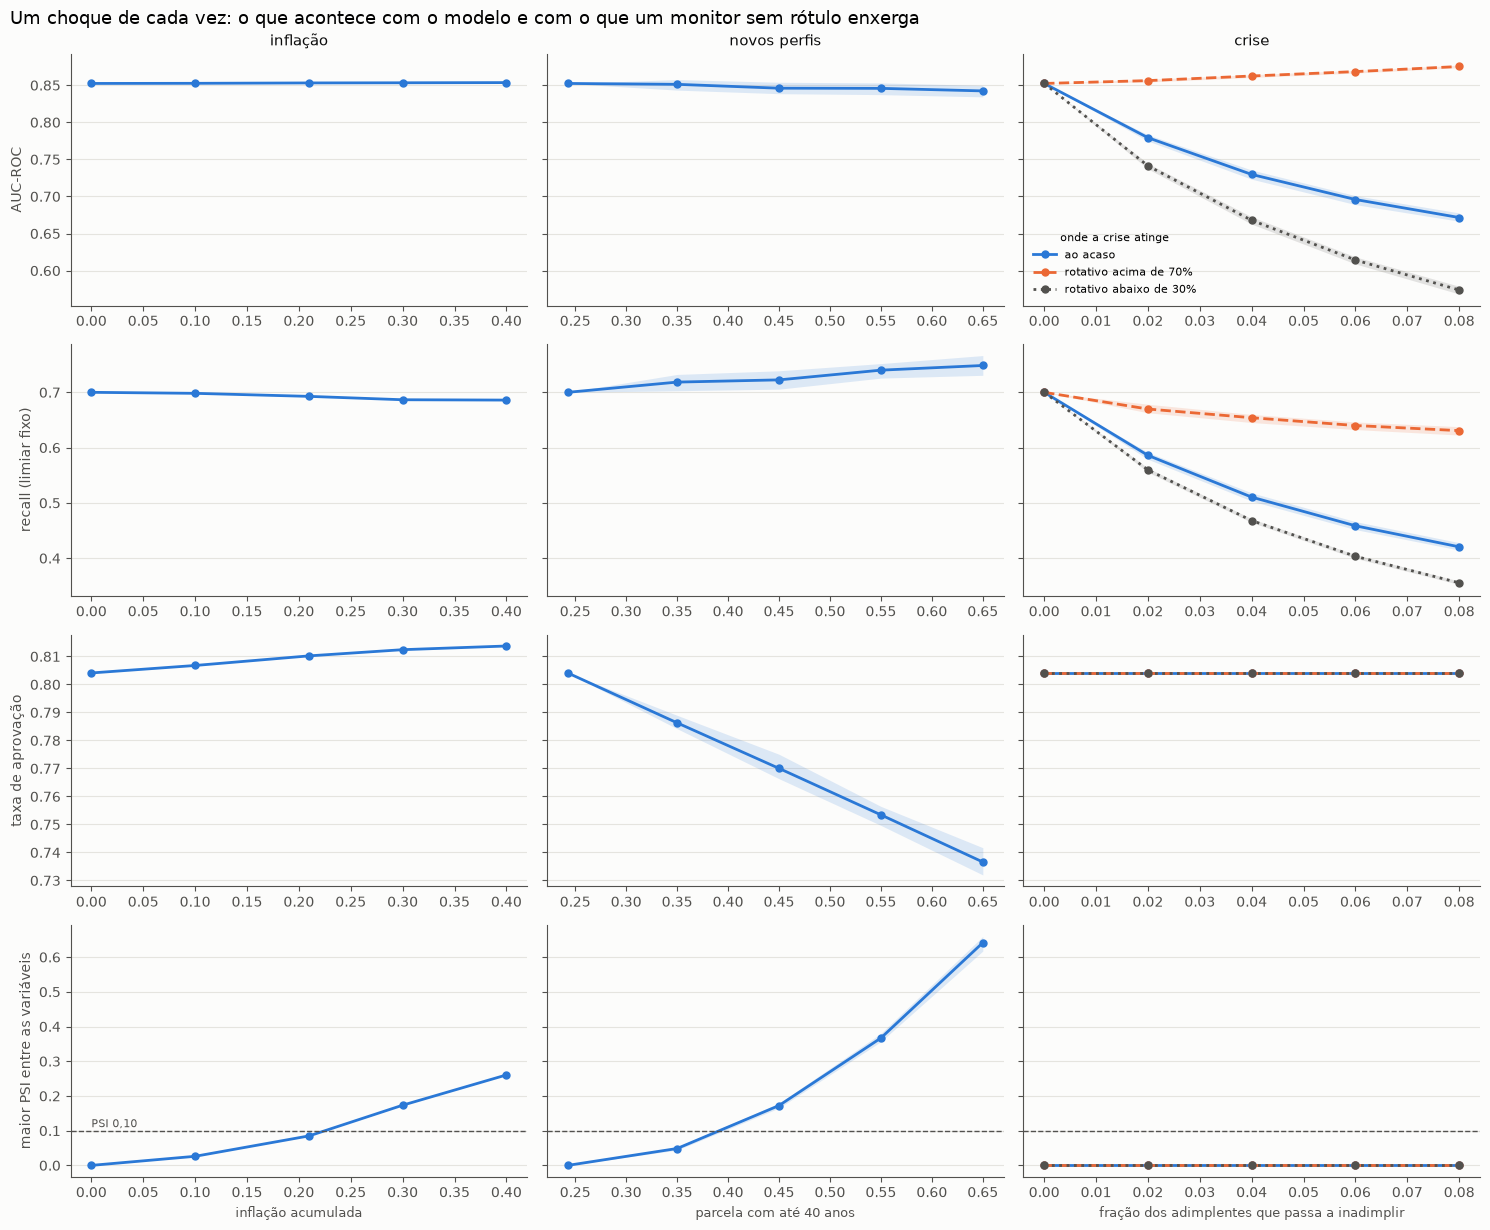

In [9]:
METRICAS = [
    ("AUC-ROC", "AUC-ROC"),
    ("recall", "recall (limiar fixo)"),
    ("aprovação", "taxa de aprovação"),
    ("PSI máximo das variáveis", "maior PSI entre as variáveis"),
]
fig, eixos = plt.subplots(len(METRICAS), 3, figsize=(15, 12.5), sharey="row")
for j, (choque, (_, _valores, rotulo_x)) in enumerate(DOSES.items()):
    locais = (
        ["ao acaso", "rotativo acima de 70%", "rotativo abaixo de 30%"]
        if choque == "crise"
        else ["ao acaso"]
    )
    for local, cor, estilo in zip(locais, [AZUL, LARANJA, TINTA_2], ["-", "--", ":"], strict=False):
        parte = doses[(doses["choque"] == choque) & (doses["local"] == local)]
        agrupado = parte.groupby("dose")
        for i, (metrica, rotulo_y) in enumerate(METRICAS):
            ax = eixos[i, j]
            media = agrupado[metrica].mean()
            ax.plot(
                media.index,
                media.values,
                color=cor,
                linestyle=estilo,
                linewidth=2,
                marker="o",
                markersize=5,
                label=local if choque == "crise" else None,
            )
            ax.fill_between(
                media.index,
                agrupado[metrica].quantile(0.05),
                agrupado[metrica].quantile(0.95),
                color=cor,
                alpha=0.15,
                linewidth=0,
            )
            if j == 0:
                ax.set_ylabel(rotulo_y)
            if i == 0:
                ax.set_title(choque)
            if i == len(METRICAS) - 1:
                ax.set_xlabel(rotulo_x, fontsize=9)
eixos[0, 2].legend(fontsize=8, loc="lower left", title="onde a crise atinge", title_fontsize=8)
for ax in eixos[3]:
    ax.axhline(0.10, color=TINTA_2, linestyle="--", linewidth=1)
eixos[3, 0].text(0.0, 0.11, "PSI 0,10", color=TINTA_2, fontsize=8)
fig.suptitle(
    "Um choque de cada vez: o que acontece com o modelo e com o que um monitor sem rótulo enxerga",
    x=0.01,
    ha="left",
    fontsize=13,
)
fig.tight_layout()
plt.show()

**Três choques, três comportamentos completamente diferentes.**

**Inflação: PSI alto, dano quase nulo.** Com 40% de inflação acumulada, o PSI da renda chega
a 0,26 — "crítico" pela convenção de mercado (acima de 0,25). A AUC-ROC não se move (0,852
para 0,854) e o recall cai 1,4 ponto. O que muda é sutil: o modelo vê todo mundo mais rico,
aprova 1 ponto a mais e passa a prever um risco médio de 6,75% contra os 6,94% reais. **H-b:
confirmada** — renda é variável fraca (EDA, IV 0,09), então deslocá-la move pouco o modelo,
por maior que seja o PSI.

**Novos perfis: o maior PSI de todos, e o modelo continua certo.** Com 65% dos clientes até
40 anos, o PSI da idade chega a 0,64. A inadimplência real sobe para 8,6%, e o risco previsto
acompanha (8,8%): **o modelo continua calibrado**. A AUC-ROC cai só 0,01, o recall até sobe, e
a taxa de aprovação cai 7 pontos — porque o modelo está recusando, corretamente, uma
população mais arriscada. Um monitor de PSI ou de taxa de aprovação dispararia aqui. **Seria
um alarme verdadeiro sobre a carteira e falso sobre o modelo.**

**Crise: o único choque que degrada o modelo — e nenhum sinal sem rótulo o vê.** Quando 4%
dos adimplentes passam a inadimplir, a AUC-ROC cai de 0,852 para 0,730 e o recall de 0,70
para 0,51. E, no mesmo cenário: **PSI das variáveis = 0, PSI do score = 0, taxa de aprovação
idêntica** (80,41%). As variáveis não mudaram, então nada calculável sem o rótulo muda.
**H-c: confirmada.**

**E onde a crise atinge muda o resultado.** As duas localizações alternativas usam o uso do
rotativo — a variável mais forte do modelo — para separar quem o modelo tende a ver como
arriscado de quem tende a ver como seguro:
- se os novos inadimplentes estão entre quem usa mais de 70% do rotativo, a AUC-ROC **sobe**
  (0,875 com 8%): o modelo já os via como arriscados, e agora acerta mais;
- se estão entre quem usa menos de 30%, a AUC-ROC **desaba** (0,574 com 8%): o choque atinge
  justamente quem o modelo aprendeu a considerar seguro.

O mesmo número de novos inadimplentes produz efeitos opostos. *Concept drift* não é um
fenômeno só: o dano depende de onde a mudança cai em relação ao que o modelo aprendeu.

## 6. Os três choques juntos: experimento fatorial

Com os três choques ligados ao mesmo tempo, a pergunta é **quanto da queda vem de cada um**.
Um experimento fatorial completo ($2^3 = 8$ combinações, cada choque ligado ou desligado, na
dose "severa" da tabela abaixo) estima o efeito de cada choque e o que eles produzem só
quando agem juntos — a **interação**.

| Choque | Dose severa |
|---|---|
| inflação | 21% (dois anos a 10%) |
| novos perfis | 55% dos clientes com até 40 anos |
| crise | 4% dos adimplentes passam a inadimplir, ao acaso |

In [10]:
SEVERO = {"inflacao": 0.21, "parcela_jovem": 0.55, "crise": 0.04}
celulas = []
for inf in (0, 1):
    for mix in (0, 1):
        for cri in (0, 1):
            parametros = {
                "inflacao": SEVERO["inflacao"] * inf,
                "parcela_jovem": SEVERO["parcela_jovem"] if mix else PARCELA_JOVEM_ATUAL,
                "crise": SEVERO["crise"] * cri,
            }
            for r in range(REPETICOES):
                celulas.append(
                    {
                        "inflação": inf,
                        "novos perfis": mix,
                        "crise": cri,
                        **medir(cenario(**parametros, semente=r)),
                    }
                )
fatorial = pd.DataFrame(celulas)
medias = fatorial.groupby(["inflação", "novos perfis", "crise"])[["AUC-ROC", "recall"]].mean()
display(medias)


def efeitos(metrica: str) -> pd.Series:
    # Contraste clássico do fatorial 2^3 com codificação -1/+1, convertido para "mudança ao
    # ligar o fator" (média com o fator ligado menos média com ele desligado).
    m = medias[metrica]
    codigo = {k: (np.array(m.index.get_level_values(k)) * 2 - 1) for k in m.index.names}
    termos = {
        "inflação": codigo["inflação"],
        "novos perfis": codigo["novos perfis"],
        "crise": codigo["crise"],
        "inflação x perfis": codigo["inflação"] * codigo["novos perfis"],
        "inflação x crise": codigo["inflação"] * codigo["crise"],
        "perfis x crise": codigo["novos perfis"] * codigo["crise"],
        "três juntos": codigo["inflação"] * codigo["novos perfis"] * codigo["crise"],
    }
    return pd.Series({nome: float((m.values * c).sum() / 4) for nome, c in termos.items()})


tabela_efeitos = pd.DataFrame({"AUC-ROC": efeitos("AUC-ROC"), "recall": efeitos("recall")})
queda_auc = medias.loc[(1, 1, 1), "AUC-ROC"] - medias.loc[(0, 0, 0), "AUC-ROC"]
queda_recall = medias.loc[(1, 1, 1), "recall"] - medias.loc[(0, 0, 0), "recall"]
print(f"tudo ligado contra nada ligado: AUC-ROC {queda_auc:+.4f} | recall {queda_recall:+.4f}")
display(tabela_efeitos)

AUC-ROC  recall
inflação novos perfis crise                 
0        0            0       0.8524  0.7001
                      1       0.7297  0.5105
         1            0       0.8458  0.7402
                      1       0.7384  0.5736
1        0            0       0.8531  0.6927
                      1       0.7301  0.5037
         1            0       0.8464  0.7374
                      1       0.7389  0.5697

tudo ligado contra nada ligado: AUC-ROC -0.1135 | recall -0.1304


,AUC-ROC,recall
inflação,0.0006,-0.0052
novos perfis,0.0011,0.0535
crise,-0.1151,-0.1782
inflação x perfis,-0.0000,0.0019
inflação x crise,-0.0001,-0.0002
perfis x crise,0.0077,0.0111
três juntos,0.0000,-0.0004


Com os três choques ligados, a AUC-ROC cai 0,114 e o recall cai 13,0 pontos. Decompondo:

| Efeito | Sobre a AUC-ROC | Sobre o recall |
|---|---:|---:|
| crise | **−0,115** (≈ 100% da queda) | **−17,8 pontos** |
| novos perfis | +0,001 | **+5,4 pontos** |
| inflação | +0,001 | −0,5 ponto |
| novos perfis × crise | +0,008 | +1,1 ponto |
| demais interações | ~0 | ~0 |

- **Toda a queda de poder discriminativo vem da crise.** Inflação e novos perfis — os dois
  choques que mais movem o PSI — contribuem com praticamente zero.
- **No recall, um choque esconde parte do outro.** A crise derruba o recall em 17,8 pontos,
  mas a nova mistura de clientes, mais arriscada e mais fácil de identificar, o empurra 5,4
  pontos para cima. Com os dois juntos, a queda observada é de 13,0 pontos. Quem olhasse só o
  recall subestimaria o estrago da crise em cerca de um quarto.
- **A interação é pequena aqui.** Os choques agem quase independentemente neste cenário.

## 7. Comparação com o que o repositório publica

O README do projeto mede a degradação com outra simulação (renda × 1,4, razão de dívida ×
1,8, um novo perfil de atraso e um *concept drift* localizado num segmento) e outro modelo
(o XGBoost publicado). As duas análises foram feitas de forma independente. A comparação:

| | README | Este notebook |
|---|---|---|
| Efeito isolado do deslocamento de renda | 0,8% da queda | ~0% |
| Efeito isolado do *concept drift* | 48,0% da queda | ≈ 100% da queda |
| Interação entre os choques | 42,1% | ≈ −7% |
| O PSI enxerga o *concept drift*? | não | não (PSI = 0) |
| A taxa de aprovação acompanha a degradação? | sim (Spearman −1,0 ao longo dos meses) | **não, na crise isolada** (aprovação idêntica) |

**Onde as duas concordam:** deslocar a renda quase não afeta o modelo, e o *concept drift* é o
principal responsável pela degradação — invisível a qualquer PSI.

**Onde divergem, e por quê:**
- **A interação.** No README ela é 42%; aqui, quase zero. O tamanho da interação depende de
  como os choques são construídos, não do modelo nem do mundo. Não deve ser lido como fato
  sobre uma carteira real.
- **O alarme sem rótulo.** No README, a taxa de aprovação acompanha a degradação mês a mês
  porque, naquela simulação, o deslocamento das variáveis e o *concept drift* crescem juntos,
  no mesmo calendário. Aqui, com os choques separados, a taxa de aprovação **não se move** na
  crise e **se move 7 pontos** com novos perfis sem que o modelo piore. O alarme detecta o
  deslocamento das variáveis que *acompanha* a crise, não a crise. O próprio README lista
  "não há detecção de *concept drift* sem rótulo" entre as limitações; este notebook mede o
  tamanho dessa limitação.

## 8. Conclusões

### As hipóteses da EDA

| Hipótese | Resultado | Evidência |
|---|---|---|
| **H-a.** O efeito da idade é em parte mediado pelo uso do rotativo | **confirmada** | 73% a 80% do excesso de risco de 26-60 anos acompanha o comportamento de crédito; o rotativo é o maior caminho (seção 3) |
| **H-b.** Deslocar a renda move pouco o modelo | **confirmada** | 40% de inflação: PSI 0,26, AUC-ROC inalterada (seção 5) |
| **H-c.** *Concept drift* não aparece em estatísticas das variáveis | **confirmada** | crise: AUC-ROC −0,12 com PSI = 0 e aprovação idêntica (seção 5) |
| **H-d.** A seleção por renda declarada está ligada a idade e risco | **confirmada, com direção** | atenua a razão de risco entre 18-25 e 61+ de 3,73× para 3,05× (seção 2) |

### O que isso significa para o problema do case

1. **A degradação silenciosa vem da mudança na relação entre perfil e risco, não da mudança
   no perfil.** Nos cenários estudados, só a crise reduz o poder do modelo. Inflação e novos
   perfis movem muito as distribuições e pouco o modelo.
2. **Nenhum sinal sem rótulo detecta a crise isolada.** PSI das variáveis, PSI do score e
   taxa de aprovação ficam exatamente iguais. Detectá-la exige o rótulo, que chega dois anos
   depois. O que dá para monitorar cedo é o deslocamento das variáveis que *costuma*
   acompanhar uma crise, sabendo que ele também dispara sem dano algum (novos perfis).
3. **O dano de um *concept drift* depende de onde ele cai.** Nos clientes que o modelo já via
   como arriscados, ele quase não machuca; nos que via como seguros, é devastador.
4. **Um choque pode mascarar outro.** Uma carteira que fica mais arriscada aumenta o recall e
   esconde cerca de um quarto da queda causada pela crise.
5. **Para equidade: tirar a idade do modelo não resolve.** A maior parte da diferença entre
   idades passa pelo comportamento de crédito, principalmente o uso do rotativo.

### Limites desta análise

- A parte 2 é **simulada**. Os choques de inflação e de novos perfis não exigem suposição
  sobre o alvo; o de crise exige (quem passa a inadimplir), e a seção 5 mostra que essa
  escolha muda o resultado.
- Na parte 1, a separação entre efeito direto e mediado depende de não haver um fator oculto
  movendo ao mesmo tempo comportamento e inadimplência — suposição não testável com esta base.
- Um único modelo de trabalho e uma única partição de validação. As conclusões sobre a
  *direção* dos efeitos são robustas às 30 repetições; os valores exatos, não necessariamente
  a outros modelos.